In [1]:
# import library

# standar library
import os
import json
import warnings
import joblib

# data & visualisasi
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

# preprocess
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV, GridSearchCV, cross_val_predict, learning_curve
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# model
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier

# metrik evaluasi
from sklearn.metrics import (
    confusion_matrix, classification_report, accuracy_score, recall_score,
    precision_score, f1_score, balanced_accuracy_score, roc_auc_score,
    average_precision_score, precision_recall_curve, roc_curve
)

# konfigurassi global
RANDOM_STATE = 42
warnings.filterwarnings("ignore")

In [2]:
# load dataset
df = pd.read_csv('/content/lung-cancer-dataset.csv')
df.head()

,GENDER,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL CONSUMING,COUGHING,SHORTNESS OF BREATH,SWALLOWING DIFFICULTY,CHEST PAIN,LUNG_CANCER
0,M,69,1,2,2,1,1,2,1,2,2,2,2,2,2,YES
1,M,74,2,1,1,1,2,2,2,1,1,1,2,2,2,YES
2,F,59,1,1,1,2,1,2,1,2,1,2,2,1,2,NO
3,M,63,2,2,2,1,1,1,1,1,2,1,1,2,2,NO
4,F,63,1,2,1,1,1,1,1,2,1,2,2,1,1,NO


In [3]:
# mengubah kolom kategorikal menjadi numerik
df['GENDER'] = df['GENDER'].map({'M': 1, 'F': 0})
df['LUNG_CANCER'] = df['LUNG_CANCER'].map({'YES': 1, 'NO': 0})

# menampilkan hasil perubahan
df.head()

,GENDER,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL CONSUMING,COUGHING,SHORTNESS OF BREATH,SWALLOWING DIFFICULTY,CHEST PAIN,LUNG_CANCER
0,1,69,1,2,2,1,1,2,1,2,2,2,2,2,2,1
1,1,74,2,1,1,1,2,2,2,1,1,1,2,2,2,1
2,0,59,1,1,1,2,1,2,1,2,1,2,2,1,2,0
3,1,63,2,2,2,1,1,1,1,1,2,1,1,2,2,0
4,0,63,1,2,1,1,1,1,1,2,1,2,2,1,1,0


In [4]:
# informasi dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 309 entries, 0 to 308
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   GENDER                 309 non-null    int64
 1   AGE                    309 non-null    int64
 2   SMOKING                309 non-null    int64
 3   YELLOW_FINGERS         309 non-null    int64
 4   ANXIETY                309 non-null    int64
 5   PEER_PRESSURE          309 non-null    int64
 6   CHRONIC DISEASE        309 non-null    int64
 7   FATIGUE                309 non-null    int64
 8   ALLERGY                309 non-null    int64
 9   WHEEZING               309 non-null    int64
 10  ALCOHOL CONSUMING      309 non-null    int64
 11  COUGHING               309 non-null    int64
 12  SHORTNESS OF BREATH    309 non-null    int64
 13  SWALLOWING DIFFICULTY  309 non-null    int64
 14  CHEST PAIN             309 non-null    int64
 15  LUNG_CANCER            309 non-null    i

In [5]:
# deskripsi dataset
df.describe()

,GENDER,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL CONSUMING,COUGHING,SHORTNESS OF BREATH,SWALLOWING DIFFICULTY,CHEST PAIN,LUNG_CANCER
count,309.000000,309.000000,309.000000,309.000000,309.000000,309.000000,309.000000,309.000000,309.000000,309.000000,309.000000,309.000000,309.000000,309.000000,309.000000,309.000000
mean,0.524272,62.673139,1.563107,1.569579,1.498382,1.501618,1.504854,1.673139,1.556634,1.556634,1.556634,1.579288,1.640777,1.469256,1.556634,0.873786
std,0.500221,8.210301,0.496806,0.495938,0.500808,0.500808,0.500787,0.469827,0.497588,0.497588,0.497588,0.494474,0.480551,0.499863,0.497588,0.332629
min,0.000000,21.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,0.000000,57.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
50%,1.000000,62.000000,2.000000,2.000000,1.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,1.000000,2.000000,1.000000
75%,1.000000,69.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,1.000000
max,1.000000,87.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,1.000000


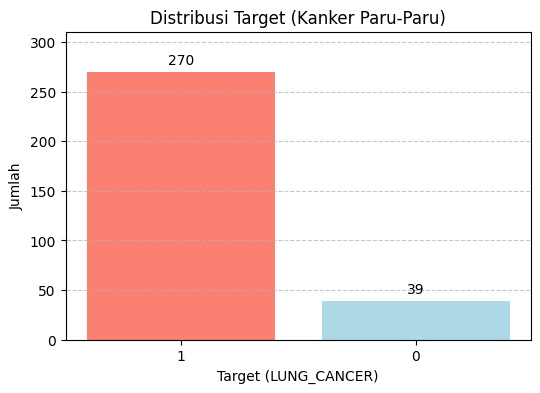

In [6]:
# visualisasi distribusi target
target_counts = df['LUNG_CANCER'].value_counts()

plt.figure(figsize=(6, 4))
bars = plt.bar(target_counts.index.astype(str), target_counts.values, color=['salmon', 'lightblue'])

plt.bar_label(bars, padding=3)

plt.title('Distribusi Target (Kanker Paru-Paru)')
plt.xlabel('Target (LUNG_CANCER)')
plt.ylabel('Jumlah')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.ylim(0, max(target_counts.values) * 1.15)
plt.show()

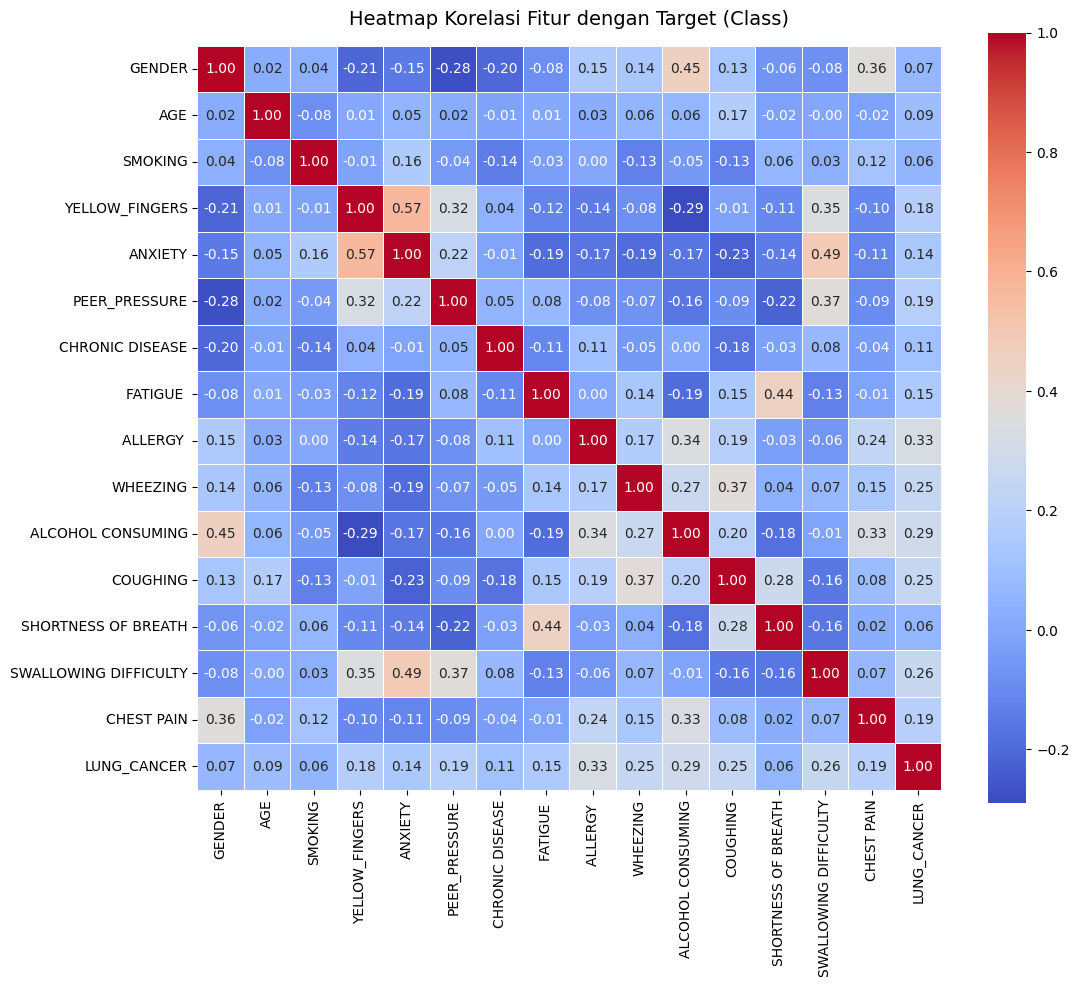

In [7]:
# hitung matriks korelasi
correlation_matrix = df.corr()

# visualisasi heatmap korelasi
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5, square=True)

plt.title('Heatmap Korelasi Fitur dengan Target (Class)', fontsize=14, pad=15)
plt.show()

In [8]:
# cek baris & kolom
df.shape

(309, 16)

In [9]:
# cek missing value
df.isnull().sum()

,0
GENDER,0
AGE,0
SMOKING,0
YELLOW_FINGERS,0
ANXIETY,0
PEER_PRESSURE,0
CHRONIC DISEASE,0
FATIGUE,0
ALLERGY,0
WHEEZING,0


In [10]:
# cek duplikasi data
df.duplicated().sum()

np.int64(33)

In [11]:
# hapus duplikasi datta
df.drop_duplicates(inplace=True)
df.duplicated().sum()

np.int64(0)

In [12]:
# baris dan kolom setelah hapus duplikasi data
df.shape

(276, 16)

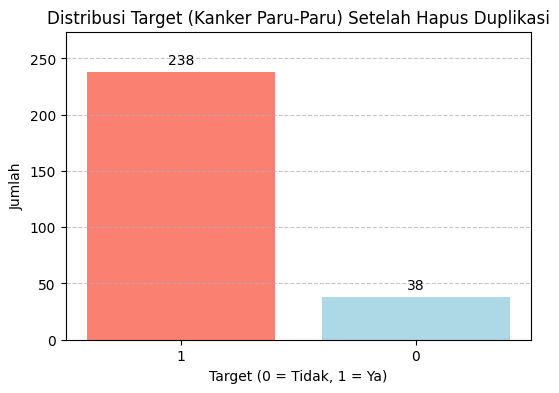

In [13]:
# visualisasi distribusi target setelah hapus duplikasi data
target_counts = df['LUNG_CANCER'].value_counts()

plt.figure(figsize=(6, 4))
bars = plt.bar(target_counts.index.astype(str), target_counts.values, color=['salmon', 'lightblue'])

plt.bar_label(bars, padding=3)

plt.title('Distribusi Target (Kanker Paru-Paru) Setelah Hapus Duplikasi')
plt.xlabel('Target (0 = Tidak, 1 = Ya)')
plt.ylabel('Jumlah')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.ylim(0, max(target_counts.values) * 1.15)
plt.show()

In [14]:
# pisah fitur (X) dengan target (y)
X = df.drop(columns=['LUNG_CANCER'])
y = df['LUNG_CANCER']

# bagi data 80% train dan 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

In [15]:
# scaling data
preprocessor = Pipeline(steps=[
    ('scaler', StandardScaler())
])

X_train_preprocessed = preprocessor.fit_transform(X_train)
X_test_preprocessed = preprocessor.transform(X_test)

features_names = X_train.columns
X_train_scaled = pd.DataFrame(X_train_preprocessed, columns=features_names)
X_test_scaled = pd.DataFrame(X_test_preprocessed, columns=features_names)

X_train_scaled.head()

,GENDER,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL CONSUMING,COUGHING,SHORTNESS OF BREATH,SWALLOWING DIFFICULTY,CHEST PAIN
0,-1.056118,0.831020,-1.126073,0.816497,-0.981981,1.037050,0.946864,0.719195,0.929735,-1.065797,0.929735,0.839897,-1.390444,-0.938265,-1.147079
1,-1.056118,1.333629,0.888042,0.816497,1.018350,1.037050,-1.056118,0.719195,-1.075576,0.938265,-1.075576,0.839897,0.719195,1.065797,-1.147079
2,-1.056118,-0.299852,-1.126073,-1.224745,-0.981981,-0.964274,0.946864,0.719195,-1.075576,-1.065797,-1.075576,-1.190623,0.719195,-0.938265,-1.147079
3,-1.056118,-0.299852,0.888042,0.816497,1.018350,1.037050,-1.056118,0.719195,0.929735,-1.065797,-1.075576,-1.190623,0.719195,1.065797,0.871780
4,-1.056118,0.202757,0.888042,0.816497,1.018350,1.037050,-1.056118,0.719195,-1.075576,0.938265,-1.075576,0.839897,0.719195,1.065797,-1.147079


 MODEL: Naive Bayes 

Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.50      0.57         8
           1       0.92      0.96      0.94        48

    accuracy                           0.89        56
   macro avg       0.79      0.73      0.76        56
weighted avg       0.88      0.89      0.89        56



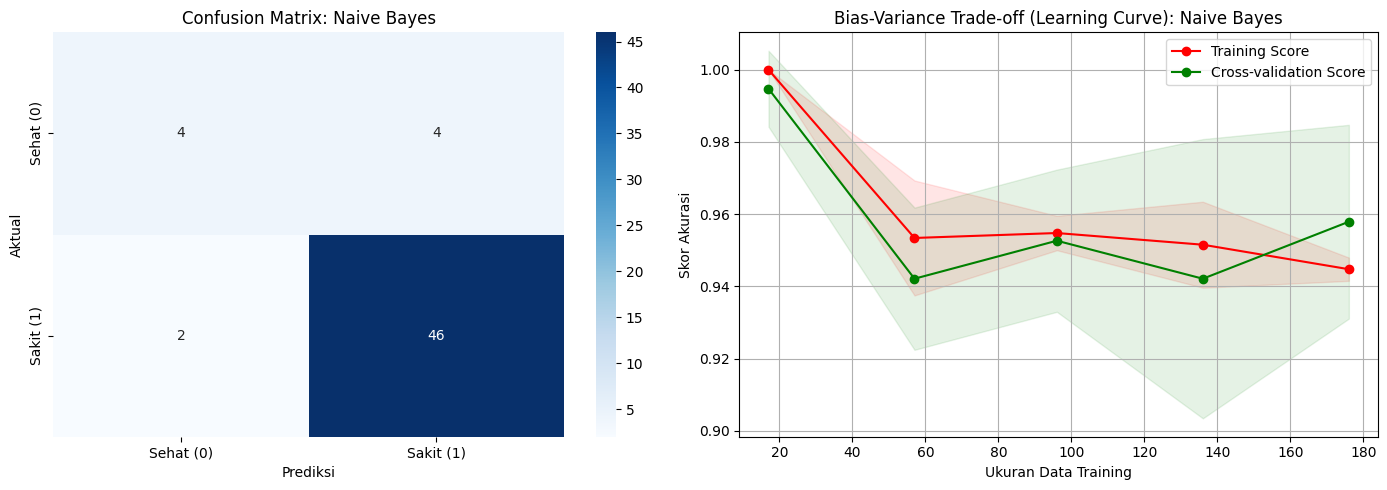




 MODEL: Logistic Regression 

Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.50      0.57         8
           1       0.92      0.96      0.94        48

    accuracy                           0.89        56
   macro avg       0.79      0.73      0.76        56
weighted avg       0.88      0.89      0.89        56



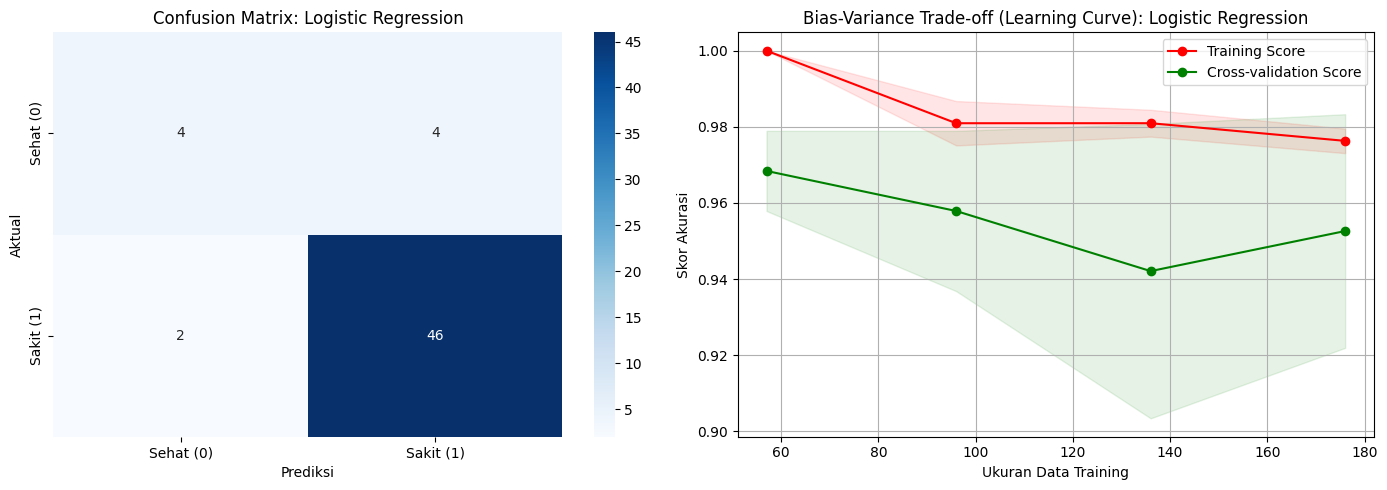




 MODEL: K-Nearest Neighbors 

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.38      0.50         8
           1       0.90      0.98      0.94        48

    accuracy                           0.89        56
   macro avg       0.83      0.68      0.72        56
weighted avg       0.88      0.89      0.88        56



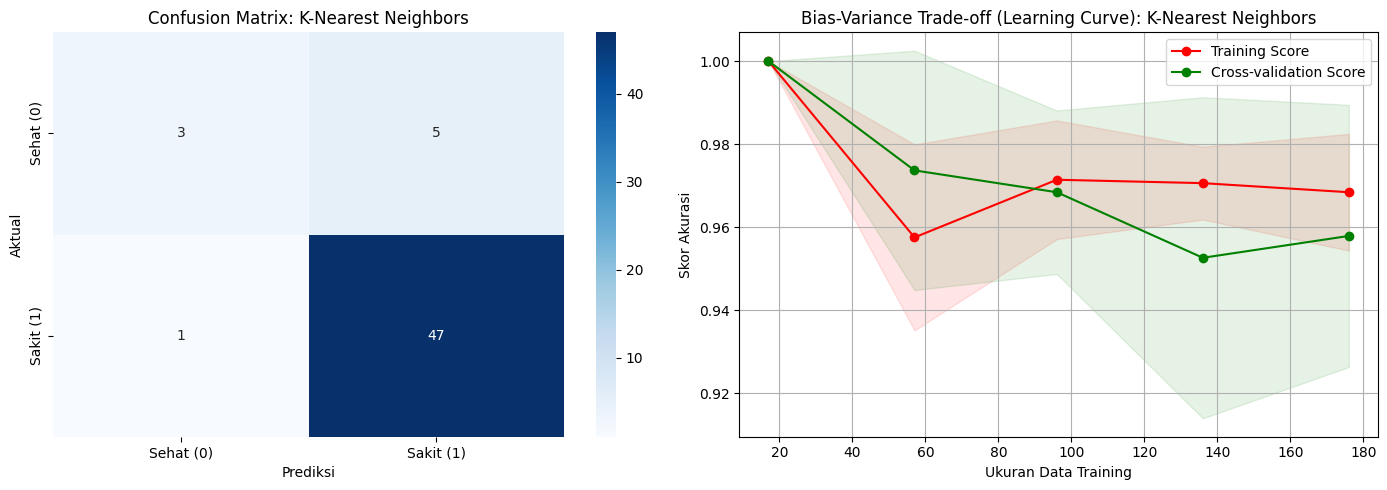




 MODEL: Support Vector Machine 

Classification Report:
              precision    recall  f1-score   support

           0       0.50      0.25      0.33         8
           1       0.88      0.96      0.92        48

    accuracy                           0.86        56
   macro avg       0.69      0.60      0.63        56
weighted avg       0.83      0.86      0.84        56



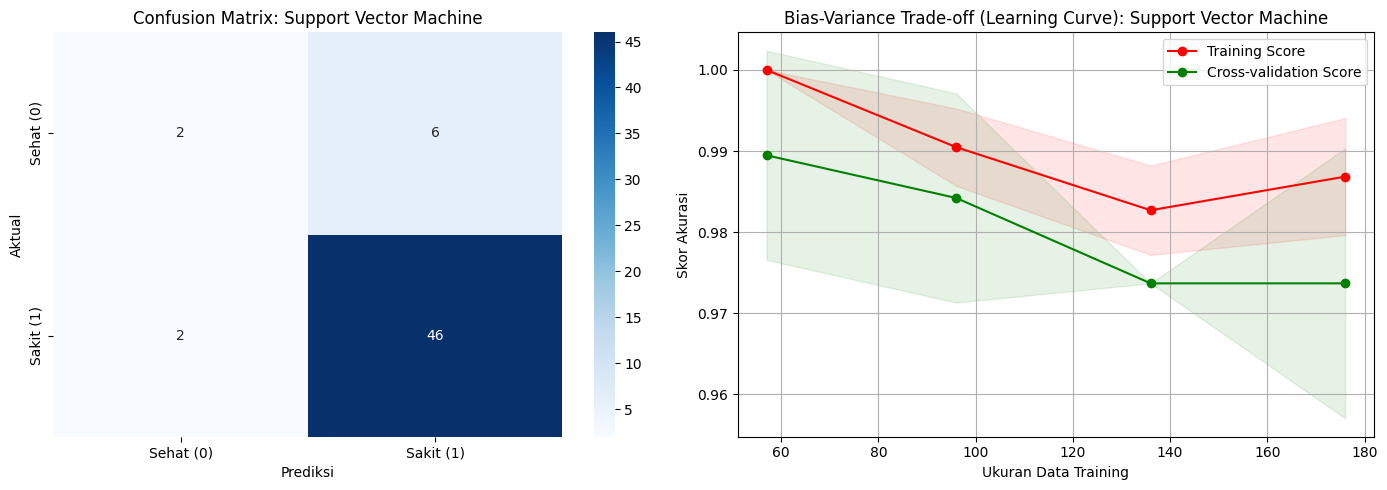




 MODEL: Decision Tree 

Classification Report:
              precision    recall  f1-score   support

           0       0.64      0.88      0.74         8
           1       0.98      0.92      0.95        48

    accuracy                           0.91        56
   macro avg       0.81      0.90      0.84        56
weighted avg       0.93      0.91      0.92        56



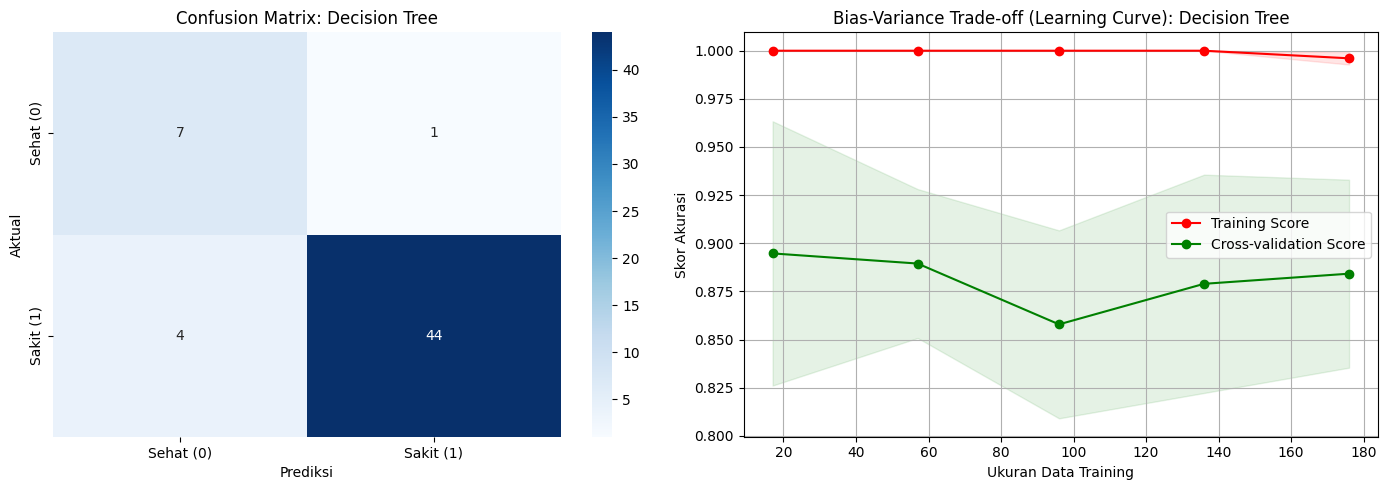




 MODEL: Random Forest 

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.75      0.75         8
           1       0.96      0.96      0.96        48

    accuracy                           0.93        56
   macro avg       0.85      0.85      0.85        56
weighted avg       0.93      0.93      0.93        56



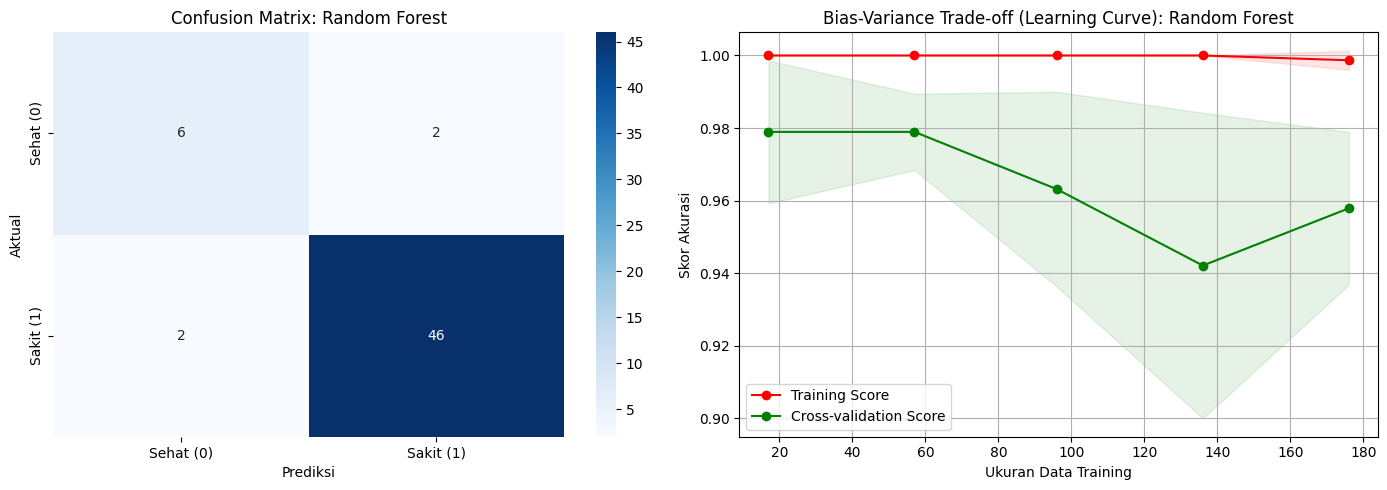




 MODEL: Gradient Boosting 

Classification Report:
              precision    recall  f1-score   support

           0       0.57      0.50      0.53         8
           1       0.92      0.94      0.93        48

    accuracy                           0.88        56
   macro avg       0.74      0.72      0.73        56
weighted avg       0.87      0.88      0.87        56



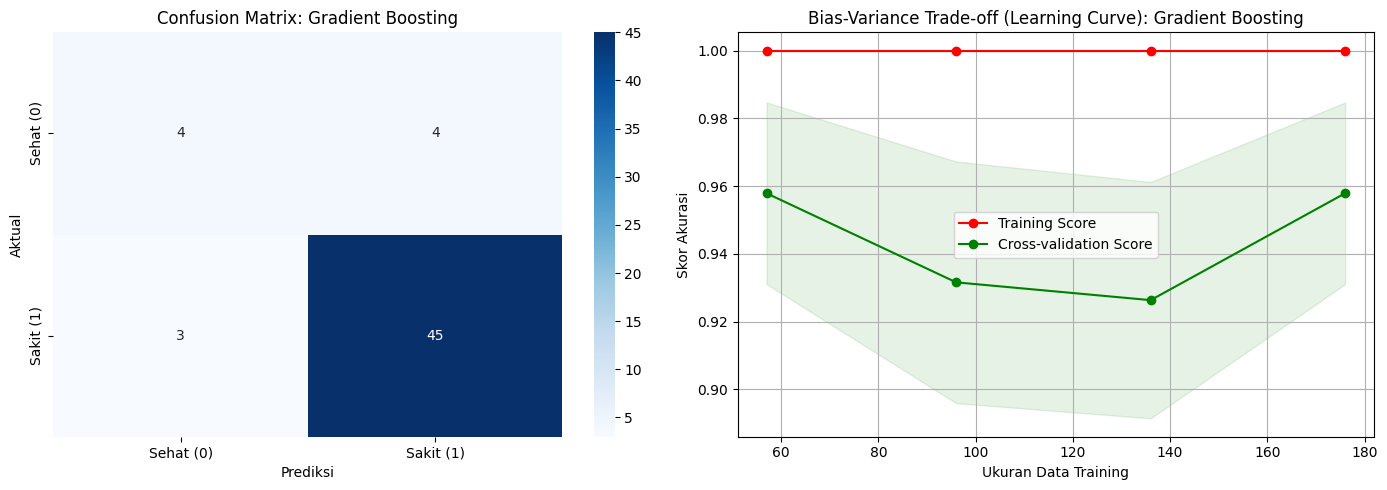




 MODEL: XGBoost 

Classification Report:
              precision    recall  f1-score   support

           0       0.50      0.38      0.43         8
           1       0.90      0.94      0.92        48

    accuracy                           0.86        56
   macro avg       0.70      0.66      0.67        56
weighted avg       0.84      0.86      0.85        56



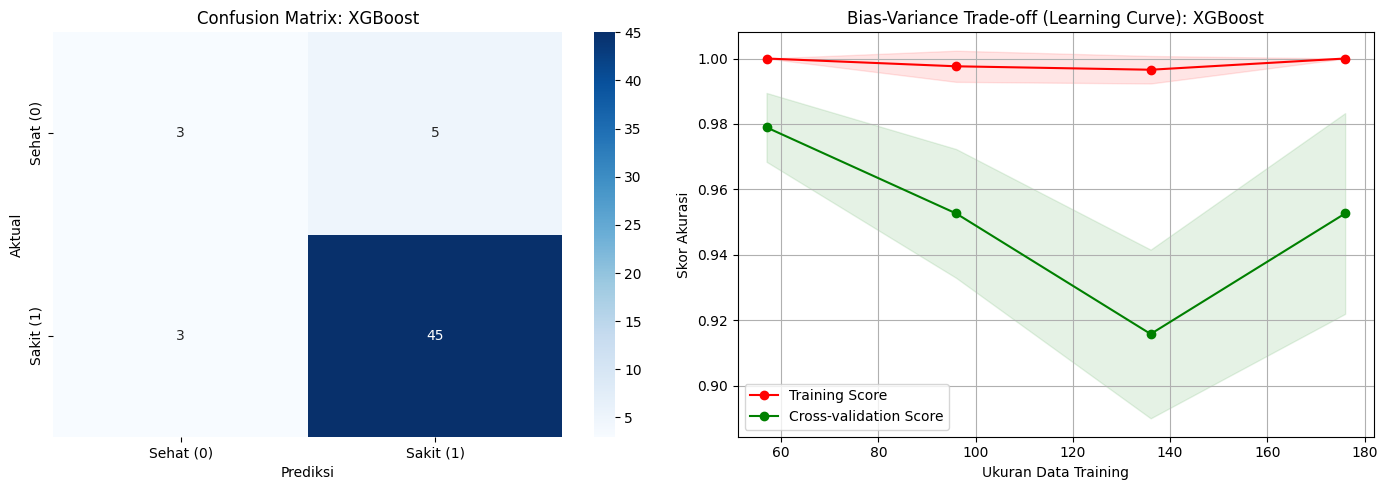




 RINGKASAN EVALUASI MODEL 
                        Accuracy  Recall  Precision  F1-Score
Naive Bayes               0.8929  0.9583     0.9200    0.9388
Logistic Regression       0.8929  0.9583     0.9200    0.9388
K-Nearest Neighbors       0.8929  0.9792     0.9038    0.9400
Support Vector Machine    0.8571  0.9583     0.8846    0.9200
Decision Tree             0.9107  0.9167     0.9778    0.9462
Random Forest             0.9286  0.9583     0.9583    0.9583
Gradient Boosting         0.8750  0.9375     0.9184    0.9278
XGBoost                   0.8571  0.9375     0.9000    0.9184


In [16]:
# definisi daftar model
models = {
    'Naive Bayes': GaussianNB(),
    'Logistic Regression': LogisticRegression(random_state=RANDOM_STATE),
    'K-Nearest Neighbors': KNeighborsClassifier(),
    'Support Vector Machine': SVC(probability=True, random_state=RANDOM_STATE),
    'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(random_state=RANDOM_STATE),
    'Gradient Boosting': GradientBoostingClassifier(random_state=RANDOM_STATE),
    'XGBoost': XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss')
}

performance_summary = {}

for name, model in models.items():
    print("="*80)
    print(f" MODEL: {name} ")
    print("="*80)

    # train model
    model.fit(X_train_scaled, y_train)

    # prediksi
    y_pred = model.predict(X_test_scaled)

    # hitung metrik evaluasi
    acc = accuracy_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    performance_summary[name] = {
        'Accuracy': acc,
        'Recall': rec,
        'Precision': prec,
        'F1-Score': f1
    }

    # 1. classification report
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))

    # 2. visualisasi confusion matrix & trade-off bias-variance (learning curve)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # plot confusion matrix
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
                xticklabels=['Sehat (0)', 'Sakit (1)'],
                yticklabels=['Sehat (0)', 'Sakit (1)'])
    axes[0].set_title(f'Confusion Matrix: {name}')
    axes[0].set_xlabel('Prediksi')
    axes[0].set_ylabel('Aktual')

    # plot learning curve (bias vs variance trade-off)
    # learning curve untuk melihat training vs validation
    train_sizes, train_scores, test_scores = learning_curve(
        model, X_train_scaled, y_train, cv=5, scoring='recall',
        train_sizes=np.linspace(0.1, 1.0, 5), random_state=RANDOM_STATE
    )

    train_mean = np.mean(train_scores, axis=1)
    train_std = np.std(train_scores, axis=1)
    test_mean = np.mean(test_scores, axis=1)
    test_std = np.std(test_scores, axis=1)

    axes[1].plot(train_sizes, train_mean, 'o-', color='r', label='Training Score')
    axes[1].plot(train_sizes, test_mean, 'o-', color='g', label='Cross-validation Score')
    axes[1].fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.1, color='r')
    axes[1].fill_between(train_sizes, test_mean - test_std, test_mean + test_std, alpha=0.1, color='g')

    axes[1].set_title(f'Bias-Variance Trade-off (Learning Curve): {name}')
    axes[1].set_xlabel('Ukuran Data Training')
    axes[1].set_ylabel('Skor Akurasi')
    axes[1].legend(loc='best')
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()
    print("\n\n")

# ringkasan semua model
df_summary = pd.DataFrame(performance_summary).T
print("="*80)
print(" RINGKASAN EVALUASI MODEL ")
print("="*80)
print(df_summary.round(4))

In [17]:
# menyimpan model terbaik Random Forest yang sudah dilatih dan preprocessor pipeline
best_model_rf = models['Random Forest']

# simpan model
model_filename = 'best_random_forest_model.joblib'
joblib.dump(best_model_rf, model_filename)
print(f"Model Random Forest berhasil disimpan ke: {model_filename}")

# simpan preprocessor scaler untuk menjamin konsistensi preprocessing data baru
preprocessor_filename = 'preprocessor_scaler.joblib'
joblib.dump(preprocessor, preprocessor_filename)
print(f"Scaler preprocessor berhasil disimpan ke: {preprocessor_filename}")

Model Random Forest berhasil disimpan ke: best_random_forest_model.joblib
Scaler preprocessor berhasil disimpan ke: preprocessor_scaler.joblib
